# 01 · ETL, validação e engenharia de atributos

**Problema (Etapa 1).** Regressão: prever a **resistência à compressão do concreto (MPa)** a partir da composição da mistura e da idade do corpo de prova.

| Item | Definição |
|---|---|
| Fonte / licença | UCI Machine Learning Repository – *Concrete Compressive Strength* (Yeh, 1998), CC BY 4.0 |
| Unidade de observação | um corpo de prova de concreto (mistura + idade de ensaio) |
| Variável-alvo | `resistencia` (MPa) |
| Atributos | cimento, escória, cinza volante, água, superplastificante, agregado graúdo, agregado miúdo (kg/m³) e idade (dias) |
| Métrica principal | **MAE** (MPa): interpretável na unidade do problema e robusta a poucos valores extremos |
| Particionamento | 20% **teste reservado** (só no notebook 05) · 15% **validação fixa** (decisões entre ciclos) · restante dividido em **4 lotes** que chegam um por ciclo |
| Limitações | dataset pequeno (1.005 amostras únicas), de laboratório; não há ordem temporal real, por isso a chegada de dados é simulada por lotes |

Este notebook incorpora o **próximo lote não processado**, sem duplicação, e gera o `cycle_id` e o `data_version` do ciclo.

In [1]:
import sys
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import warnings
warnings.filterwarnings("ignore")
import json
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image

from src.utils import preparar_ambiente, carregar_config, carregar_contexto, salvar_contexto, dir_evidencias, configurar_mlflow
preparar_ambiente()
cfg = carregar_config()
pd.set_option("display.width", 160)

In [2]:
from src.ingestao import (carregar_estado, salvar_estado, proximo_lote, carregar_treino_acumulado,
                          salvar_treino_acumulado, versao_dados)
from src.preprocessamento import diagnostico, limpar_lote, criar_atributos, ATRIBUTOS_DERIVADOS
from src.drift import detectar_drift
from src.utils import novo_cycle_id, gatilho_execucao, DIR_CICLO
import shutil

# área temporária do ciclo começa vazia
if DIR_CICLO.exists():
    shutil.rmtree(DIR_CICLO)

estado = carregar_estado(cfg)
lote = proximo_lote(cfg, estado)
cycle_id = novo_cycle_id()
ev = dir_evidencias(cycle_id)
print("cycle_id:", cycle_id)
print("Lotes já incorporados:", estado["lotes_processados"])
print("Próximo lote:", lote.name if lote else "nenhum (ciclo reutiliza os dados atuais)")

cycle_id: c20261122T215332Z-gh2
Lotes já incorporados: ['lote_01.csv']
Próximo lote: lote_02.csv


## Diagnóstico do lote recebido (antes do tratamento)

In [3]:
treino_anterior = carregar_treino_acumulado(cfg)
if lote is not None:
    bruto = pd.read_csv(lote)
    diag_antes = diagnostico(bruto, cfg)
    print(f"{lote.name}: {len(bruto)} linhas | duplicadas no lote: {bruto.duplicated().sum()}")
    display(diag_antes)
    diag_antes.to_csv(ev / "diagnostico_lote_antes.csv", index=False)
else:
    bruto, diag_antes = None, None

lote_02.csv: 100 linhas | duplicadas no lote: 0


,coluna,ausentes,fora_da_faixa,outliers_iqr,min,mediana,max
0,cimento,0,0,0,108.30,253.900,522.00
1,escoria,0,0,0,0.00,24.000,342.10
2,cinza_volante,0,0,0,0.00,0.000,200.10
3,agua,0,0,0,126.60,181.600,236.70
4,superplastificante,3,0,2,0.00,7.500,32.20
5,agregado_graudo,0,0,1,801.00,967.000,1134.30
6,agregado_miudo,0,0,0,594.00,781.100,992.60
7,idade,0,0,0,3.00,28.000,56.00
8,resistencia,0,0,0,6.81,33.065,74.36


## Validação e limpeza

Regras (definidas em `config.yaml`):
- **Esquema**: todas as colunas esperadas devem existir; caso contrário o ciclo falha (e nada é promovido).
- **Faixas físicas plausíveis**: linhas fora das faixas são rejeitadas (ex.: água negativa).
- **Duplicatas**: removidas dentro do lote e em relação ao que já foi incorporado (hash por linha).
- **Ausentes**: mantidos e **imputados pela mediana dentro do Pipeline**, ajustado só no treino.
- **Outliers (IQR)**: apenas reportados. Idades de 180–365 dias e resistências altas são fisicamente reais; removê-las tiraria do modelo justamente os casos de longa idade.

In [4]:
if lote is not None:
    limpo, rel = limpar_lote(bruto, treino_anterior, cfg)
    display(pd.DataFrame([rel]).T.rename(columns={0: "linhas"}))
else:
    limpo, rel = None, {"linhas_recebidas": 0, "linhas_aceitas": 0}

,linhas
linhas_recebidas,100
removidas_alvo_ausente,0
removidas_fora_da_faixa,0
removidas_duplicadas_no_lote,0
removidas_ja_incorporadas,0
ausentes_para_imputacao,3
linhas_aceitas,100


## Monitoramento de drift do lote novo (recurso adicional – critério 10)
Compara cada variável do lote novo com o treino acumulado (teste KS, α = 0,05).

,variavel,ks_estatistica,p_valor,media_referencia,media_lote,drift
0,agregado_graudo,0.1261,0.156356,974.291,964.251,False
1,agregado_miudo,0.1155,0.233885,776.843,784.014,False
2,cimento,0.0868,0.571766,273.800,277.930,False
3,agua,0.0805,0.664935,180.123,177.976,False
4,resistencia,0.0774,0.710502,31.851,34.068,False
5,cinza_volante,0.0742,0.756985,62.125,57.253,False
6,superplastificante,0.0741,0.769682,6.347,7.399,False
7,idade,0.0737,0.763778,22.057,24.780,False
8,escoria,0.0587,0.936078,70.303,77.619,False


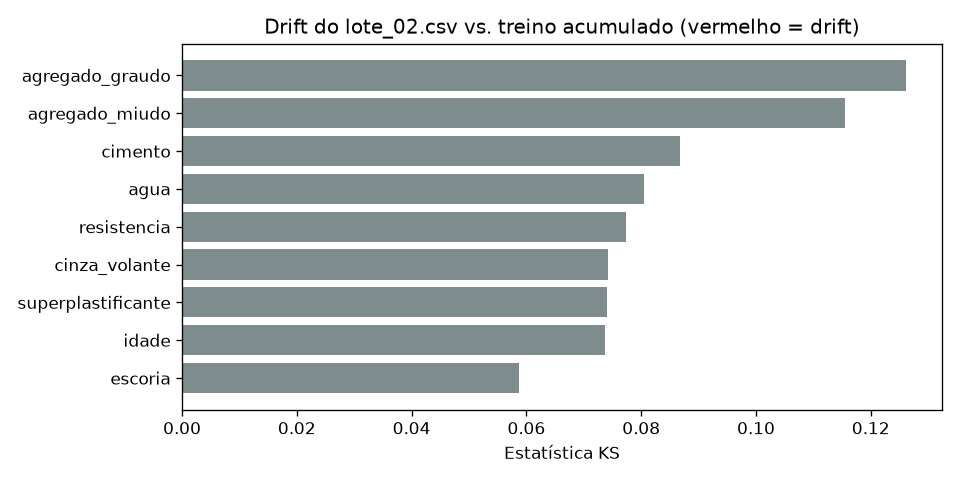

0/9 variáveis com drift (KS, p<0.05)


In [5]:
drift_resumo, drift_alerta, tabela_drift = None, False, None
if lote is not None and treino_anterior is not None and len(limpo):
    cols = cfg["dados"]["atributos_originais"] + [cfg["dados"]["alvo"]]
    tabela_drift, frac, drift_alerta = detectar_drift(treino_anterior, limpo, cols, cfg)
    n_drift = int(tabela_drift["drift"].sum())
    drift_resumo = f"{n_drift}/{len(cols)} variáveis com drift (KS, p<{cfg['drift']['alpha']})" + (" – ALERTA" if drift_alerta else "")
    display(tabela_drift)
    tabela_drift.to_csv(ev / "drift.csv", index=False)
    fig, ax = plt.subplots(figsize=(8, 4))
    cores = ["#c0392b" if d else "#7f8c8d" for d in tabela_drift["drift"]]
    ax.barh(tabela_drift["variavel"], tabela_drift["ks_estatistica"], color=cores)
    ax.invert_yaxis(); ax.set_xlabel("Estatística KS"); ax.set_title(f"Drift do {lote.name} vs. treino acumulado (vermelho = drift)")
    fig.tight_layout(); fig.savefig(ev / "drift.png", dpi=120); plt.close(fig)
    display(Image(str(ev / "drift.png")))
    print(drift_resumo)
else:
    print("Drift não avaliado (primeiro ciclo ou sem dados novos).")

## Incorporação, versionamento dos dados e diagnóstico depois

In [6]:
if lote is not None:
    treino = limpo if treino_anterior is None else pd.concat([treino_anterior, limpo], ignore_index=True)
    salvar_treino_acumulado(cfg, treino)
    estado["lotes_processados"].append(lote.name)
else:
    if treino_anterior is None:
        raise RuntimeError("Não há lotes nem treino acumulado: nada para processar.")
    treino = treino_anterior

data_version = versao_dados(treino, estado["lotes_processados"])
estado["ciclos"].append({"cycle_id": cycle_id, "lote": lote.name if lote else None, "data_version": data_version})
salvar_estado(cfg, estado)

diag_depois = diagnostico(treino, cfg)
diag_depois.to_csv(ev / "diagnostico_treino_depois.csv", index=False)
print(f"Treino acumulado: {len(treino)} linhas | data_version = {data_version}")
display(diag_depois)
print("Atributos derivados:", ATRIBUTOS_DERIVADOS)
display(criar_atributos(treino).head())

Treino acumulado: 436 linhas | data_version = v2-fb30fed2


,coluna,ausentes,fora_da_faixa,outliers_iqr,min,mediana,max
0,cimento,0,0,0,108.30,257.750,540.0
1,escoria,0,0,0,0.00,22.000,342.1
2,cinza_volante,0,0,0,0.00,24.500,200.1
3,agua,0,0,4,121.80,183.000,236.7
4,superplastificante,3,0,3,0.00,7.000,32.2
5,agregado_graudo,0,0,0,801.00,968.000,1134.3
6,agregado_miudo,0,0,10,594.00,781.100,992.6
7,idade,0,0,0,1.00,28.000,56.0
8,resistencia,0,0,4,3.32,31.225,74.7


Atributos derivados: ['relacao_agua_cimento', 'aglomerante_total', 'relacao_agua_aglomerante', 'log_idade']


,cimento,escoria,cinza_volante,agua,superplastificante,agregado_graudo,agregado_miudo,idade,resistencia,relacao_agua_cimento,aglomerante_total,relacao_agua_aglomerante,log_idade
0,375.0,0.0,0.0,186.0,0.0,1038.0,758.0,7,26.06,0.496000,375.0,0.496000,2.079442
1,252.5,0.0,0.0,185.7,0.0,1111.6,784.3,7,11.48,0.735446,252.5,0.735446,2.079442
2,303.6,139.9,0.0,213.5,6.2,895.5,722.5,28,33.42,0.703228,443.5,0.481398,3.367296
3,425.0,106.3,0.0,153.5,16.5,852.1,887.1,56,64.30,0.361176,531.3,0.288914,4.043051
4,213.7,0.0,174.7,154.8,10.2,1053.5,776.4,28,40.15,0.724380,388.4,0.398558,3.367296


In [7]:
mlflow = configurar_mlflow(cfg)
with mlflow.start_run(run_name=f"etl_{cycle_id}") as run:
    mlflow.set_tags({"cycle_id": cycle_id, "data_version": data_version, "etapa": "etl", "gatilho": gatilho_execucao()})
    mlflow.log_params({"lote": lote.name if lote else "nenhum", "lotes_incorporados": ",".join(estado["lotes_processados"])})
    mlflow.log_metrics({"linhas_treino": len(treino), **{k: v for k, v in rel.items() if isinstance(v, int)}})
    if tabela_drift is not None:
        mlflow.log_metrics({"drift_variaveis": int(tabela_drift["drift"].sum()), "drift_alerta": int(drift_alerta)})
    for arq in ev.glob("*"):
        mlflow.log_artifact(str(arq), artifact_path="etl")

salvar_contexto({
    "cycle_id": cycle_id, "data_version": data_version, "lote": lote.name if lote else None,
    "n_treino": len(treino), "gatilho": gatilho_execucao(), "etl": rel,
    "drift_resumo": drift_resumo, "drift_alerta": bool(drift_alerta), "run_etl": run.info.run_id,
})
print("Contexto do ciclo salvo.")

Contexto do ciclo salvo.
